# Age and Gender Distortion
* This assignment is based on the [research by Guilbeault, Delecourt, and Srinivasa Desikan (2025)](https://www.nature.com/articles/d41586-025-02974-0), which highlights the phenomenon of *gendered ageism* in online content.  
* By analyzing large datasets of images and text, the authors found that online media consistently **depict women as significantly younger than men** in identical professional roles, distorting the actual demographics of the workforce.  
* The study reveals that **Artifical Intelligence Μodels** (LLMs), not only reflect but potentially amplify these biases.  
* For instance, when generating CVs, AI models tended to associate older age with higher professional quality for men, but not for women, reinforcing social norms that value *youth in women* and *experience in men*.
* In this assignment, we will work through some of their results using their public [data](https://github.com/drguilbe/distortion_age_gender_online/).

---

> Grigoris Alexandrou <br />
> t8220004@aueb.gr <br />
> Department of Management Science and Technology <br />
> Athens University of Economics and Business  

## Setting the Scene 
For the second assignment, I did the following steps:
* Used again [uv](https://docs.astral.sh/uv/).
* Created a folder named *2_Assignment* with this file in it.
* Run the following commands:
    - `uv init --bare`  
    - `uv python pin 3.13`  
    - `uv venv`  
    - `uv add pandas numpy jupyter plotly matplotlib altair scipy scikit-learn seaborn pingouin --link-mode=copy`
    - `uv run jupyter notebook .`
* The project was available at <http://localhost:8888/tree>.

## Correlation Between Age and Gender

* First of all, we will analyse the gender-age associations in **GPT2-Large** model. This is the largest (albeit old) model available from *OpenAI*.
* In order to do that, the researchers captured how the internal representation of texts by GPT2-Large are mapped to age and gender dimensions.
* I downloaded the `GPT2-large-dimensions.csv` from [here](https://drive.google.com/drive/folders/1-4cy2gYDDRZ8tnZ6ZXES3jcwxNiNucG3?usp=sharing) and placed it the `data` folder. 
* Before we dive into the csv file, let's import some of the necessary modules, more of them will be used later on.

In [334]:
import pandas as pd
import pingouin as pg
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
import seaborn as sns
import os
import statsmodels.api as sm
import statsmodels.formula.api as smf
import altair as alt
from scipy.stats import ttest_ind, ttest_1samp, gaussian_kde
from matplotlib.patches import Patch
os.makedirs('outputs', exist_ok=True)

* Okay, now we can read the csv file.

In [335]:
FOLDER = "data"
gpt2_large_dimensions = pd.read_csv(f"{FOLDER}/GPT2-large-dimensions.csv")
gpt2_large_dimensions.head()

,Social.Category,Source,gender.main,gender_norm.main,gender.ext,gender_norm.ext,gender.red,gender_norm.red,age.main,age_norm.main,age.ext,age_norm.ext,age.red,age_norm.red
0,abandoned infant,GPT2,-0.197087,0.540877,0.001662,0.527162,-0.108243,0.561858,-0.070237,0.357426,-0.004732,0.319985,-0.055446,0.419423
1,abandoned person,GPT2,-0.199134,0.535577,0.001236,0.523567,-0.110507,0.554830,-0.065570,0.382294,-0.001178,0.343708,-0.048989,0.477159
2,abiogenist,GPT2,-0.231156,0.452671,0.004317,0.549545,-0.151075,0.428889,-0.097012,0.214761,-0.026444,0.175097,-0.063784,0.344863
3,able-bodied seaman,GPT2,-0.162948,0.629264,0.001341,0.524456,-0.067956,0.686928,-0.042036,0.507690,0.016286,0.460250,-0.043687,0.524568
4,able seaman,GPT2,-0.181426,0.581424,0.002330,0.532793,-0.089043,0.621465,-0.055517,0.435856,0.006879,0.397472,-0.049394,0.473540


* In this csv file, each `Social.Category` is mapped to a number between on the age and sex dimension.
* So, we will calculate the **Pearson** correlation between age and gender.
* Before calculating the correlation, we need to select the appropriate metrics from the dataset.
* As we can see above, the authors provide multiple columns of the *age* and *gender*.

* The **Gender** and **Age** dimensions in a vector space are defined by taking the difference between two sets of opposing words (e.g., *man* - *woman*).
* The suffixes indicate which specific list of words were used to define the axis:
    * **.main**: Main Set. This uses the standard set of antonym pairs (e.g., *he/she*, *father/mother*, *old/young*) defined in the primary methodology of the paper. This is the benchmark configuration.
    * **.ext**: Extended Set. This uses a larger, more comprehensive list of keyword pairs to define the axis, capturing broader nuances but potentially introducing noise.
    * **.red**: Reduced Set. This uses a smaller, strictly curated subset of pairs to test for robustness.
* The most critical distinction is between the raw scores (e.g., `gender.main`) and the normalized scores (e.g., `gender_norm.main`).
    * **Raw Scores** (e.g., `gender.main`): These represent the *dot product* (projection) of a word's vector onto the gender acis.
    * **Normalized Scores** (e.g., `gender_norm.main`): These represent the **cosine similarity**. The vectors are normalized to unit length before projection.
* Which one should we use though?
* Raw projections are influenced by the *magnitude* (length) of the word vector. In models like GPT2, vector length is often correlated with word frequency.
* A word might appear to have a high "male" score simply because it is a very frequent word with a long vector, not because it is semantically gendered.
* On the other hand, normalized scores isolate the *angle* (direction) of the word in the vector space.
* Bias is defined by semantic orientation (e.g., is "nurse" pointing in the same direction as "female"?), regardless of how frequent the word "nurse" is.
* *Conclusion*: To strictly measure bias without the interference of word frequency, we must use the **normalized** dimensions derived from the **main** seed set.
* So we will proceed with: `age_norm.main` and `gender_norm.main` columns.

In [336]:
correlation_results = pg.corr(x=gpt2_large_dimensions['age_norm.main'],
                              y=gpt2_large_dimensions['gender_norm.main'])
correlation_results

,n,r,CI95%,p-val,BF10,power
pearson,3495,0.872559,"[0.86, 0.88]",0.0,inf,1.0


* This statistical analysis provides decisive evidence of a strong association between age and gender representations in GPT2 Large.
* **Pearson Correlation (r = 0.872)**: This indicates a very strong positive linear relationship. It implies that as a social category becomes more semantically associated with *men*, it also becomes strongly associated with *older age*. Conversely, categories associated with women are strongly linked to younger age.
* **Bayes Factor (BF10 = inf)**: The infinite Bayes Factor offers extreme evidence in favor of the alternative hypothesis (that a correlation exists) over the null hypothesis.
* **Statistical Significance**: The p-value = 0 and maximum Statistical Power = 1 confirm that this observation is robust and not due to random chance.
* So, the LLM does not treat gender and age as independent variables but conflates them, reproducing **gendered ageism bias**.

* Now, we will show that the results are *robust to alternative methods* for extracting age and gender associations by creating all pairwise correlations and putting them on **heatmaps**.
* So we have to calculate the pairwise correlations between the **Main**, **Extended** and **Reduced** sets for both Age and Gender.
* High correlations among these sets indicate that bias is consistent (robust) regardless of the specific antonyms used.

* Let's start with the *Age Heatmap*.
* We will create a separate dataframe with the normalized columns from the original dataframe.
* *Note*: I should have renamed the columns before I begin the assignment, becaused the standardized naming in python is with underscore `_` not dot `.`. I will do it now.

In [337]:
gpt2_large_dimensions = gpt2_large_dimensions.rename(columns={
    'Social.Category': 'Social_Category',
    'gender.main': 'gender_main',
    'gender_norm.main': 'gender_norm_main',
    'gender.ext': 'gender_ext',
    'gender_norm.ext': 'gender_norm_ext',
    'gender.red': 'gender_red',
    'gender_norm.red': 'gender_norm_red',
    'age.main': 'age_main',
    'age_norm.main': 'age_norm_main',
    'age.ext': 'age_ext',
    'age_norm.ext': 'age_norm_ext',
    'age.red': 'age_red',
    'age_norm.red': 'age_norm_red'
}).copy()

* Also, we will rename the columns to be exactly like the assignment.

In [338]:
age_df = gpt2_large_dimensions[['age_norm_red', 'age_norm_ext', 'age_norm_main']].rename(columns={
    'age_norm_red': 'age_red',
    'age_norm_ext': 'age_ext',
    'age_norm_main': 'age_score'
})

* Now, we will do the same for the *Gender*.

In [339]:
gender_df = gpt2_large_dimensions[['gender_norm_red', 'gender_norm_ext', 'gender_norm_main']].rename(columns={
    'gender_norm_red': 'gender_red',
    'gender_norm_ext': 'gender_ext',
    'gender_norm_main': 'gender_score'
})

* And we are ready to plot the two **heatmaps** and also *save as svg files*.
* We can use matplotlib for the visualisation.
* We will create a custom color map with the colors that are used in the expected heatmap on the assignment.

In [340]:
colors = ['#EF886B', '#CC403A', '#B40426']
cmap = LinearSegmentedColormap.from_list('custom_red', colors, N=100)

* First we have the *Age*.

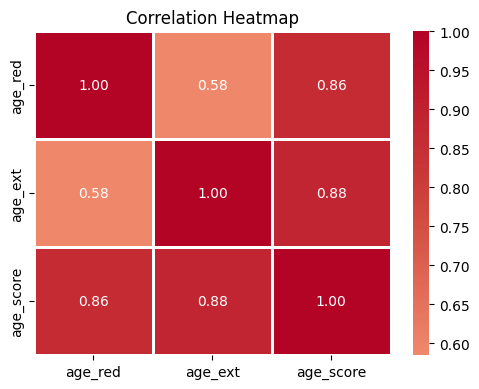

In [341]:
plt.figure(figsize=(5, 4))
plt.title('Correlation Heatmap')
sns.heatmap(
    age_df.corr(), 
    annot=True, 
    cmap=cmap,
    fmt='.2f', 
    linewidths=1,
    linecolor='white'
)
plt.tight_layout()
plt.savefig('outputs/correlation_heatmap_age.svg', format='svg')
plt.show()

* Next up we have the *Gender*.

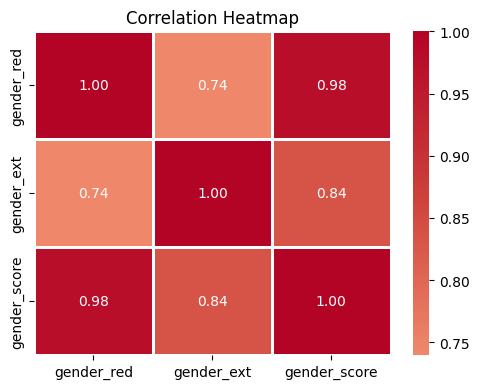

In [342]:
plt.figure(figsize=(5, 4))
plt.title('Correlation Heatmap')
sns.heatmap(
    gender_df.corr(), 
    annot=True, 
    cmap=cmap, 
    fmt='.2f', 
    linewidths=1,
    linecolor='white'
)
plt.tight_layout()
plt.savefig('outputs/correlation_heatmap_gender.svg', format='svg')
plt.show()

* I noticed that we also have to save an svg file named `correlation_heatmap.svg`.
* To create that heatmap we should concat combine the two dataframes: `age_df` and `gender_df`.

In [343]:
age_and_gender_df = pd.concat([age_df, gender_df], axis=1)

* And now let's draw the heatmap following the same logic as before but with a new custom color map.


In [344]:
colors = ['#F0CDBB', '#F08A6C', '#C83836', '#B40426']
cmap = LinearSegmentedColormap.from_list('custom_red', colors, N=100)

In [345]:
plt.figure(figsize=(10, 8))
plt.title('Correlation Heatmap')
sns.heatmap(
    age_and_gender_df.corr(),
    annot=True, 
    cmap=cmap,
    fmt='.2f', 
    linewidths=1,
    linecolor='white'
)
plt.tight_layout()
plt.savefig('outputs/correlation_heatmap.svg', format='svg')
plt.close()

* *Note*: I am using custom color maps because when I set `cmap=Reds` it wasn't the same. Now, it is pretty close in my opinion.
* The heatmaps demonstrate high pairwise correlations across all three variations.
* Specifically, the **Main** is strongly correlated with both **Extended** and **Reduced** sets.
* So, the association between gender and age is **robust**.

## Relationship between Age and Gender
* Now we will run a regression between the normalized age and gender measures.
* We will use the `statsmodel.formula.api` aka `smf` for the OLS Regression.
* We will specify the *age_norm_main* first as the Dep. Variable and after the *gender_norm_main*. 

In [346]:
ag_model = smf.ols("age_norm_main ~ gender_norm_main", data=gpt2_large_dimensions)
ag_results = ag_model.fit()
ag_results.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:          age_norm_main   R-squared:                       0.761
Model:                            OLS   Adj. R-squared:                  0.761
Method:                 Least Squares   F-statistic:                 1.114e+04
Date:                Mon, 15 Dec 2025   Prob (F-statistic):               0.00
Time:                        13:02:21   Log-Likelihood:                 5425.6
No. Observations:                3495   AIC:                        -1.085e+04
Df Residuals:                    3493   BIC:                        -1.083e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
====================================================================================
                       coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------
Intercept           -0.0211      0.003     -6.510      0.000      -0.027      -0.015
gender_norm_main     0.7450      0.007    105.565      0.000       0.731       0.759
==============================================================================
Omnibus:                      829.901   Durbin-Watson:                   1.255
Prob(Omnibus):                  0.000   Jarque-Bera (JB):             4643.267
Skew:                           1.012   Prob(JB):                         0.00
Kurtosis:                       8.271   Cond. No.                         9.75
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

* Looking at the summary report table, we can see thet **R-Squared = 0.761**. 
* This means that the model explains *76.1%* of the variance in age associations based solely on gender associations.
* This indicates that gender is a primary driver of how age is represented in the embedding space.
* Also, the **coefficient = 0.7450**.
* This indicates a strong positive slope. For every unit increase in the "Male" direction, the "Age" score increases by 0.7450 units.
* **Significance:** with a p-value of 0, this relationship is statistically significant.

* Based on the estimated coefficients, the linear model describing the relationship between the normalized gender and age dimnesions is given by:  
$$ Age_{norm} = 0.7450 \times Gender_{norm} - 0.0211  $$

* Following that, we will make a **regression plot**, highlighting representative categories.
* We will create a list with the categories that are mentioned in the plot of the paper.
* After that we can filter the dataset based on the highlighted categories and create a new dataframe.

In [347]:
highlight_categories = [
    'intern', 'cook', 'homoeopath', 'secretary', 'novice',
    'military personnel', 'elected official', 'chairman of the board', 
    'director of research', 'chief of staff'
]
highlight_df = gpt2_large_dimensions[
    gpt2_large_dimensions['Social_Category'].isin(highlight_categories)
].copy()

* Let's set up the plot.
* First of all we have to *plot all the points* with black color.
* Then, we have to draw the **regression line** from the model above with red color.
* After that, we will set the colors for the highlighted points.
    * The colors are *based on the gender score*: Yellow if it is low, Blue if it is high.
* In order to show the annotation as good as possible (as I can), *I make some calculations about the highlighted dots*.
    * For instance, if the dot has a *low gender score* then the annotation should be on the *left*.
    * Also, if the dot is *above the regression line*, the annotation should be *above* the dot.
* Finally, after some calculations, we add the **highlighted points** and the labeling and *save as an svg file*.
* *Note*: The claculations on how to add the annotations are just for clarity and better visualisation.

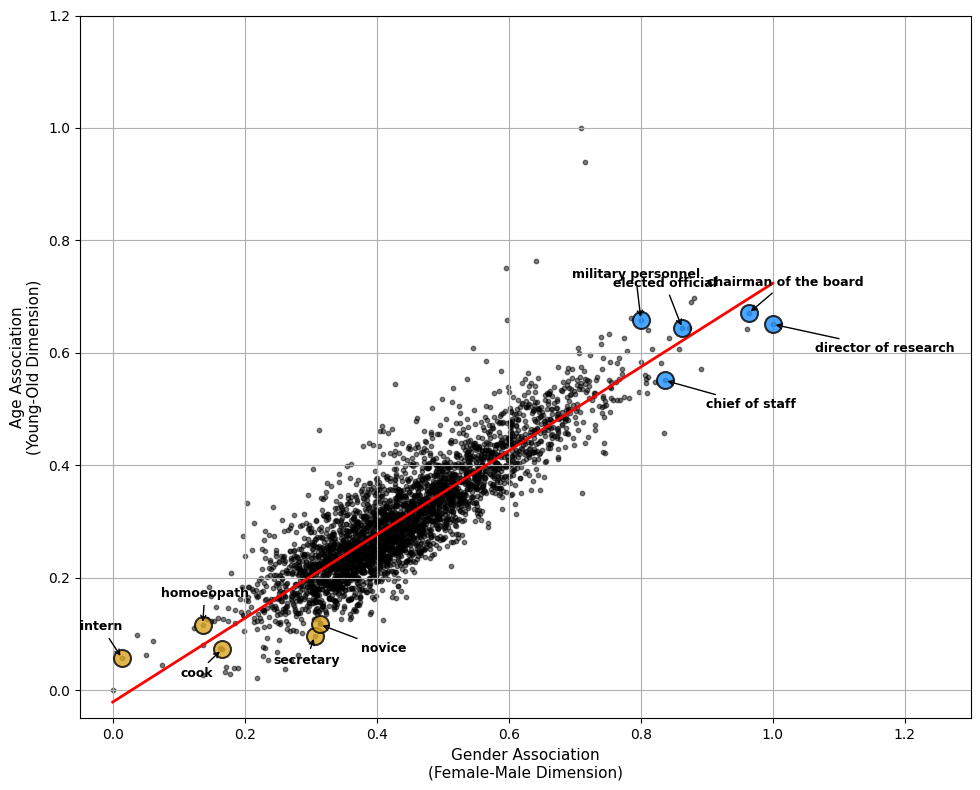

In [348]:
import numpy as np
plt.figure(figsize=(10, 8))

plt.scatter(gpt2_large_dimensions['gender_norm_main'], 
            gpt2_large_dimensions['age_norm_main'], 
            alpha=0.5, 
            s=10,
            color='black',
            zorder=1)

x_line = np.linspace(gpt2_large_dimensions['gender_norm_main'].min(), 
                     gpt2_large_dimensions['gender_norm_main'].max(), 
                     100)
y_line = ag_results.params['Intercept'] + ag_results.params['gender_norm_main'] * x_line
plt.plot(x_line, y_line, color='red', linewidth=2, zorder=2)

for category in highlight_categories:
    cat_data = highlight_df[highlight_df['Social_Category'] == category]
    if len(cat_data) > 0:
        x_point = cat_data['gender_norm_main'].iloc[0]
        y_point = cat_data['age_norm_main'].iloc[0]
        
        y_predicted = ag_results.params['Intercept'] + ag_results.params['gender_norm_main'] * x_point
        
        if x_point < 0.5:
            color = '#DAA520'
        else:
            color = '#1E90FF'
        
        if category == 'novice':
            x_offset = 30  
            y_offset = -20 
        elif category == 'chairman of the board':
            x_offset = -30
            y_offset = 20 
        elif x_point >= 0.5 and y_point > y_predicted:
            x_offset = -50
            y_offset = 30
        else:
            if x_point < 0.5:
                x_offset = -30  
            else:
                x_offset = 30   
            
            if y_point > y_predicted:
                y_offset = 20   
            else:
                y_offset = -20  
        
        plt.scatter(x_point, y_point, 
                    s=150,
                    color=color,
                    alpha=0.8,
                    zorder=3,
                    edgecolors='black',
                    linewidths=1.5)
        
        plt.annotate(category, 
                    xy=(x_point, y_point),
                    xytext=(x_offset, y_offset),
                    textcoords='offset points',
                    fontsize=9,
                    fontweight='bold',
                    arrowprops=dict(arrowstyle='->', 
                                   connectionstyle='arc3,rad=0',
                                   color='black',
                                   lw=1))

plt.xlabel('Gender Association\n(Female-Male Dimension)', fontsize=11)
plt.ylabel('Age Association\n(Young-Old Dimension)', fontsize=11)
plt.grid(True, alpha=1)

plt.xlim(-0.05, 1.30)  
plt.ylim(-0.05, 1.20)  

plt.tight_layout()
plt.savefig('outputs/age_gender_regression_plot.svg', format='svg')
plt.show()

* But, why did the researches show us these specific highlighted data points?
* It could be interesting to create an **interactive plot**, so that by hovering over the points, we will be able to see the details of other categories.
* In order to create the interactive plot, we will use the `altair` library.

* First, we will prepare our data for visualisation.
* We will create a copy of the dataset to avoid modifying the original data.
* Then we can identify which categories should be highlighted in the plot (without the annotation)
* We can create a `category_type` column that assignes colors based on gender associations:
    * Female-associated are the categories with low gender score and they will be shown in yellow color again.
    * Male-associated are the categories with high gender score and they will be shown again in blue color.
    * All the rest will appear as black

In [349]:
plot_df = gpt2_large_dimensions.copy()
plot_df['is_highlighted'] = plot_df['Social_Category'].isin(highlight_categories)

def get_color(row):
    if row['is_highlighted']:
        if row['gender_norm_main'] < 0.5:
            return 'Female-associated'
        else:
            return 'Male-associated'
    else:
        return 'Other'

plot_df['category_type'] = plot_df.apply(get_color, axis=1)

* Next, we will calculate the regression line using the coefficients from our OLS model.
* This line represents the predicted relationship between gender and age associations across all categories.
* We can create a range of x values (gender) from 0 to 1 and then calculate the corresponding y values (age) using our regression equation:
$$ Age_{norm} = 0.7450 \times Gender_{norm} - 0.0211  $$
* This line will be overlaid on our scatterplot to show the overall trend.

In [350]:
intercept = ag_results.params['Intercept']
slope = ag_results.params['gender_norm_main']

regression_line = pd.DataFrame({
    'gender_norm_main': np.linspace(0, 1, 100)
})
regression_line['age_norm_main'] = intercept + slope * regression_line['gender_norm_main']

* Now, we will create the main scatterplot.
* When hovering to any point the user will see: the category name, the gender and age score rounded in 2 decimals.
* This way we can explore all the data. 

In [351]:
scatter = alt.Chart(plot_df).mark_circle(
    stroke='black'
).encode(
    x=alt.X('gender_norm_main:Q', 
            scale=alt.Scale(domain=[0, 1]),
            title='Gender Association (Female-Male Dimension)'),
    y=alt.Y('age_norm_main:Q', 
            scale=alt.Scale(domain=[0, 1]),
            title='Age Association (Young-Old Dimension)'),
    size=alt.condition(
        alt.datum.is_highlighted,
        alt.value(150),
        alt.value(20)
    ),
    color=alt.Color('category_type:N',
        scale=alt.Scale(
            domain=['Female-associated', 'Male-associated', 'Other'],
            range=['#DAA520', '#1E90FF', '#111111']
        ),
        legend=None
    ),
    opacity=alt.condition(
        alt.datum.is_highlighted,
        alt.value(0.8),
        alt.value(0.5)
    ),
    strokeWidth=alt.condition(
        alt.datum.is_highlighted,
        alt.value(1.5),
        alt.value(0)
    ),
    tooltip=[
        alt.Tooltip('Social_Category:N', title='social_category'),
        alt.Tooltip('gender_norm_main:Q', title='gender_norm', format='.2f'),
        alt.Tooltip('age_norm_main:Q', title='age_norm', format='.2f')
    ]
).properties(
    width=700,
    height=600
)

* Now, we create the regression line.
* And combine the two of them and *save as an html file*.

In [ ]:
line = alt.Chart(regression_line).mark_line(
    color='red',
    strokeWidth=2
).encode(
    x='gender_norm_main:Q',
    y='age_norm_main:Q'
)

reg_plot_interactive = (line + scatter).configure_axis(
    gridColor='lightgray',
    gridOpacity=0.3
).configure_view(
    strokeWidth=0
)

reg_plot_interactive.save('outputs/regression_plot_interactive.html')
reg_plot_interactive

alt.LayerChart(...)

* Let's examine the rest of the outliers that are not highlighted by the authors.

* Exploring the interactive plot, we can see that the dataset is actually quite noisy and contains many issues that were not highlighted in the paper.

* First of all, there are many items that are not occupations at all.
* We find random terms like *ex*, *hero*, *villain*, *psychopath*, *messiah*, *cigarette smoker* etc.
* There are also sensitive categories related to race and religion (e.g., *jew*, *anti-semite*, *person of color*, *non-jew*, *coloured person* etc) mixed in with jobs.
* These should probably have been cleaned out.

* Another thing I want to comment is that there are logical erros and duplicates and some of the model's associations simply don't make sense.
* The model ranks *brother-in-law- as older than *father-in-law*, which at most cases is impossible.
* Paradoxically, *old woman* scores the same on the Male axis as *old man*.
* The data wasn't cleaned for duplicates or spelling variations either (e.g., *neighbor* and *neighbour* or *person of color* and *colored person*)

* It seems that the authors likely *cherry-picked* the clearest examples for their static plots to tell a clean story.
* However, looking at the full dataset reveals that the model's bias is real, but the data itself is much messier than I expected.

## Aplification via Google Search
* For this section we will use the `experiment_control.csv` and the `experiment_treatment.csv` files from the official [data](https://drive.google.com/drive/folders/1-4cy2gYDDRZ8tnZ6ZXES3jcwxNiNucG3).
* Let's read the data and take a look at them.

In [354]:
treatment = pd.read_csv(f"{FOLDER}/experiment_treatment.csv")
treatment.head()

,subj,category,age,gender,condition
0,55a55bd7fdf99b790558627c,artstudent,18.63,Female,Image
1,55a55bd7fdf99b790558627c,astronaut,30.29,Female,Image
2,55a55bd7fdf99b790558627c,automotiveengineer,36.06,Male,Image
3,55a55bd7fdf99b790558627c,chiefexecutiveofficer,46.11,Female,Image
4,55a55bd7fdf99b790558627c,computerexpert,30.70,Female,Image


In [355]:
control = pd.read_csv(f"{FOLDER}/experiment_control.csv")
control.head()

,category,subj,age,ideal_age,condition,gender
0,aeronauticalengineer,55595b70fdf99b387ae30d2b,50.27,50.40,Control,Male
1,aeronauticalengineer,55900dcffdf99b3f7aada3f5,41.82,42.49,Control,Not Sure
2,aeronauticalengineer,57210674951c9b0011d3eaaa,32.71,27.08,Control,Not Sure
3,aeronauticalengineer,5843241166ef8c00018955fd,39.95,40.35,Control,Male
4,aeronauticalengineer,59baa339ab8d830001fe56f5,40.08,40.08,Control,Male


* Okay so, the **control** group estimated the age of a category *aka occupation* without seeing a related image.
* The participants in the **treatment** group searched on Google for images of the category before estimating the age. 
* We need to analyze if the image search introduces any distortion in age perception.

* To measure the effect of viewing images, we need a baseline.
* The baseline is the average age estimate for each category from the *control* group (participants who didn't see an image).

In [356]:
control_avg = control.groupby('category')['age'].mean().reset_index()
control_avg.columns = ['category', 'control_avg_age']

* Now, we will calculate how much each treatment participant's estimate differs from this baseline.

In [357]:
treatment_merged = treatment.merge(control_avg, on='category', how='left')
treatment_merged['age_difference'] = treatment_merged['age'] - treatment_merged['control_avg_age']

* Now, we can separate the *treatment* data based on whether participants uploaded images of women or men.
* The `age_difference` variable shows how much higher or lower each participant's estimate was compared to the control baseline.

In [358]:
female_diff = treatment_merged[treatment_merged['gender'] == 'Female']['age_difference'].dropna()
male_diff = treatment_merged[treatment_merged['gender'] == 'Male']['age_difference'].dropna()

* Now we can create the density plot showing the distribution of age differences for participants who uploaded female vs male images.
* The vertical lines indicate the mean difference for each group.
* The dotted line at zero, represents the control baseline.
* Negative values mean that age estimates younger than control
* Positive values mean that age estimates older than control.

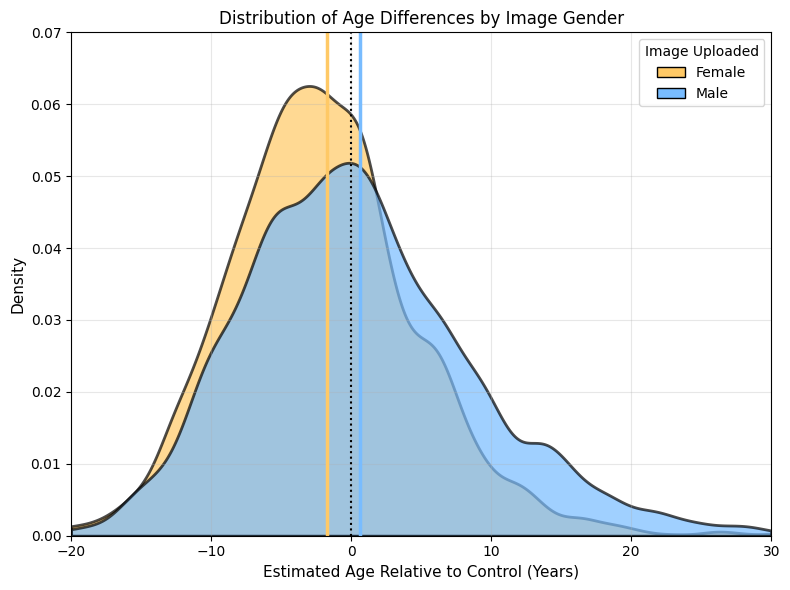

In [359]:
plt.figure(figsize=(8, 6))

colors = {'Female': '#FFC966', 'Male': '#78BCFF'}

x_range = np.linspace(-20, 30, 1000)
kde_female = gaussian_kde(female_diff, bw_method=0.14)
kde_male = gaussian_kde(male_diff, bw_method=0.14)

plt.fill_between(x_range, kde_female(x_range), alpha=0.7, color=colors['Female'], 
                 edgecolor='black', linewidth=2)
plt.fill_between(x_range, kde_male(x_range), alpha=0.7, color=colors['Male'], 
                 edgecolor='black', linewidth=2)

plt.axvline(x=female_diff.mean(), color=colors['Female'], linestyle='-', linewidth=2.5)
plt.axvline(x=male_diff.mean(), color=colors['Male'], linestyle='-', linewidth=2.5)
plt.axvline(x=0, color='black', linestyle=':', linewidth=1.5)

plt.xlabel('Estimated Age Relative to Control (Years)', fontsize=11)
plt.ylabel('Density', fontsize=11)
plt.title('Distribution of Age Differences by Image Gender', fontsize=12)
plt.xlim(-20, 30)
plt.ylim(0, 0.07)
plt.grid(True, alpha=0.3)

legend_elements = [
    Patch(facecolor=colors['Female'], edgecolor='black', label='Female'),
    Patch(facecolor=colors['Male'], edgecolor='black', label='Male')
]

plt.legend(handles=legend_elements, title='Image Uploaded', loc='upper right', 
           fontsize=10, frameon=True)

plt.tight_layout()
plt.show()

* Now we will show the same results with the authors.
* We will quantify the effects observed in the visualisation through 3 hypothesis tests.
* Let's get the `female_ages` and the `male_ages`.

In [360]:
female_ages = treatment_merged[treatment_merged['gender'] == 'Female']['age'].dropna()
male_ages = treatment_merged[treatment_merged['gender'] == 'Male']['age'].dropna()

* Do participants who uploaded female images estimate significantly different ages than those who uploaded male images?
* We will run independent samples t-test (Welch's t-test, which does not assume equal variances)
* The null hypothesis $H_0$ is Mean age estimate (female) = Mean age estimate (male)

In [361]:
t_female_male, p_female_male = ttest_ind(female_ages, male_ages, equal_var=False)
diff_female_male = female_ages.mean() - male_ages.mean()

print("=" * 70)
print("Test 1: Female vs Male Images")
print("=" * 70)
print(f"Difference: {diff_female_male:.2f} years")
print(f"t-statistic: {t_female_male:.2f}")
print(f"p-value: {p_female_male:.2e}")
print("=" * 70)

Test 1: Female vs Male Images
Difference: -5.46 years
t-statistic: -19.07
p-value: 5.24e-78


* This is the same with the authors. 
* The participants who uploaded an image of a woman estimated the average age of a category (occupation) to be 5.46 years younger than those who uploaded an image of a man.
* The t-statistic is -19.07.
* The p-value is 5.24e-78 which is less than $2.2 \times 10^{−16}$

* Do participants who uploaded female images estimate ages differently from the control group baseline?
* We will run One-Sample t-test against zero (testing if the mean age difference from control is significantly different from 0)
* The null hypothesis $H_0$ is Mean age difference = 0 (no effect of female images)

In [362]:
t_female_control, p_female_control = ttest_1samp(female_diff, 0)

print("\n" + "=" * 70)
print("Test 2: Female Images vs Control Baseline")
print("=" * 70)
print(f"Mean difference from control: {female_diff.mean():.2f} years")
print(f"t-statistic: {t_female_control:.2f}")
print(f"p-value: {p_female_control:.2e}")
print("=" * 70)


Test 2: Female Images vs Control Baseline
Mean difference from control: -1.75 years
t-statistic: -11.32
p-value: 4.82e-29


* This shows us that uploading an image of a woman led the participants to estimate significantly lower age for each occupation, by 1.75 years, compared with the control participants.
* The t-statistic is -11.32 and the p-value is 4.82e-29 which is also less than $2.2 \times 10^{−16}$

* Do participants who uploaded male images estimate ages differently from the control group baseline?
* We will run One-Sample t-test against zero
* The null hypothesis $H_0$ is Mean age difference = 0 (no effect of male images)

In [363]:
t_male_control, p_male_control = ttest_1samp(male_diff, 0)

print("\n" + "=" * 70)
print("Test 3: Male Images vs Control Baseline")
print("=" * 70)
print(f"Mean difference from control: {male_diff.mean():.2f} years")
print(f"t-statistic: {t_male_control:.2f}")
print(f"p-value: {p_male_control:.4f}")
print("=" * 70)


Test 3: Male Images vs Control Baseline
Mean difference from control: 0.64 years
t-statistic: 3.42
p-value: 0.0006


* Finally, uploading an image of a man, led the participants to estimate a significantly higher age for each occupation, by 0.64 years, compared with those in the control condition.
* The t-statistic is 3.42 and the p-value is 0.0006, the same with the paper.

## Investigate the Amplification
* To investigate the amplification, we will take the treatment and the control together as one dataset and we will run a regression with `age` as the dependent variable.
* The independent variables will be:
    * `condition * gender`
    * `category`
    * `subj`


* Let's see one more time the dataframes

In [364]:
treatment.head()

,subj,category,age,gender,condition
0,55a55bd7fdf99b790558627c,artstudent,18.63,Female,Image
1,55a55bd7fdf99b790558627c,astronaut,30.29,Female,Image
2,55a55bd7fdf99b790558627c,automotiveengineer,36.06,Male,Image
3,55a55bd7fdf99b790558627c,chiefexecutiveofficer,46.11,Female,Image
4,55a55bd7fdf99b790558627c,computerexpert,30.70,Female,Image


In [365]:
control.head()

,category,subj,age,ideal_age,condition,gender
0,aeronauticalengineer,55595b70fdf99b387ae30d2b,50.27,50.40,Control,Male
1,aeronauticalengineer,55900dcffdf99b3f7aada3f5,41.82,42.49,Control,Not Sure
2,aeronauticalengineer,57210674951c9b0011d3eaaa,32.71,27.08,Control,Not Sure
3,aeronauticalengineer,5843241166ef8c00018955fd,39.95,40.35,Control,Male
4,aeronauticalengineer,59baa339ab8d830001fe56f5,40.08,40.08,Control,Male


* Let's concat them in order to take them together as one dataset.

In [366]:
treatment_control = pd.concat([treatment, control], ignore_index=True)
treatment_control = treatment_control[treatment_control['gender'].isin(['Male', 'Female'])].copy()

* Now, let's define and execute the regression model.
* We will use *C()* to define the categorical variables.
* For the gender we will use *Treatment* to add the reference Male.

In [367]:
investigate_amplification_model = smf.ols(
    formula="age ~ condition * C(gender, Treatment(reference='Male')) + category + subj", 
    data=treatment_control
).fit()

* And now we will report the results of the regression.

In [368]:
investigate_amplification_model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                    age   R-squared:                       0.586
Model:                            OLS   Adj. R-squared:                  0.560
Method:                 Least Squares   F-statistic:                     22.30
Date:                Mon, 15 Dec 2025   Prob (F-statistic):               0.00
Time:                        13:02:23   Log-Likelihood:                -28066.
No. Observations:                8514   AIC:                         5.715e+04
Df Residuals:                    8005   BIC:                         6.074e+04
Df Model:                         508                                         
Covariance Type:            nonrobust                                         
=======================================================================================================================================
                                                                          coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------------------------------------------------------------
Intercept                                                              44.1459      1.524     28.963      0.000      41.158      47.134
condition[T.Image]                                                     -4.7819      1.447     -3.305      0.001      -7.618      -1.946
C(gender, Treatment(reference='Male'))[T.Female]                       -2.1919      0.288     -7.614      0.000      -2.756      -1.628
category[T.appliedscientist]                                           -0.1997      0.772     -0.259      0.796      -1.713       1.314
category[T.artstudent]                                                -15.9195      0.769    -20.691      0.000     -17.428     -14.411
category[T.artteacher]                                                 -1.5589      0.760     -2.050      0.040      -3.049      -0.068
category[T.astronaut]                                                   0.8480      0.756      1.121      0.262      -0.635       2.331
category[T.astrophysicist]                                              5.5395      0.746      7.422      0.000       4.076       7.002
category[T.automotiveengineer]                                         -3.0039      0.741     -4.056      0.000      -4.456      -1.552
category[T.bookkeeper]                                                 -0.1153      0.754     -0.153      0.878      -1.593       1.362
category[T.cardiologist]                                                7.2159      0.752      9.600      0.000       5.743       8.689
category[T.chiefexecutiveofficer]                                      10.7181      0.744     14.401      0.000       9.259      12.177
category[T.chiropractor]                                                0.8699      0.749      1.161      0.246      -0.599       2.338
category[T.clarinetist]                                                -3.6484      0.738     -4.943      0.000      -5.095      -2.202
category[T.climatologist]                                               1.0234      0.759      1.348      0.178      -0.465       2.511
category[T.computerexpert]                                             -5.7173      0.738     -7.751      0.000      -7.163      -4.271
category[T.cosmeticsurgeon]                                             4.5735      0.752      6.085      0.000       3.100       6.047
category[T.dietician]                                                  -2.3849      0.757     -3.150      0.002      -3.869      -0.901
category[T.dressmaker]                                                  0.9079      0.740      1.227      0.220      -0.542       2.358
category[T.editorinchief]                                               7.6277      0.758  

* It is true that the table takes a lot of space...

* Main Effect of Condition: The Image filter has a significant negative effect on perceived age for the reference group (Male).
* It reduces the perceived age of men by 4.78 years.
* Interaction Effect: The interaction term `condition[T.Image]:C(gender, Treatment(reference='Male'))[T.Female]` is statistically significant with coef = -0.8495 and p-value = 0.007.

* The significant negative interaction coefficient indicates that the age-reducing effect of the Image is amplified for women.
* While the filter makes men look approximately *4.78 years younger*, it makes women look *an additional 0.85 years younger* so total reduction of 5.63 years.

* Now, we will do another regression with only `category` and `subj` as the independent variables.
* And we will use this model to predict the age for the combined treatment and control dataset.

In [369]:
amplification_model = smf.ols(
    formula="age ~ category + subj", 
    data=treatment_control
).fit()

* Now, we will add the new columns.

In [370]:
treatment_control['predicted'] = amplification_model.predict(treatment_control)
treatment_control['residuals'] = treatment_control['age'] - treatment_control['predicted']

* And we are ready to create the plots.
* Starting with the Predicted / Condition.

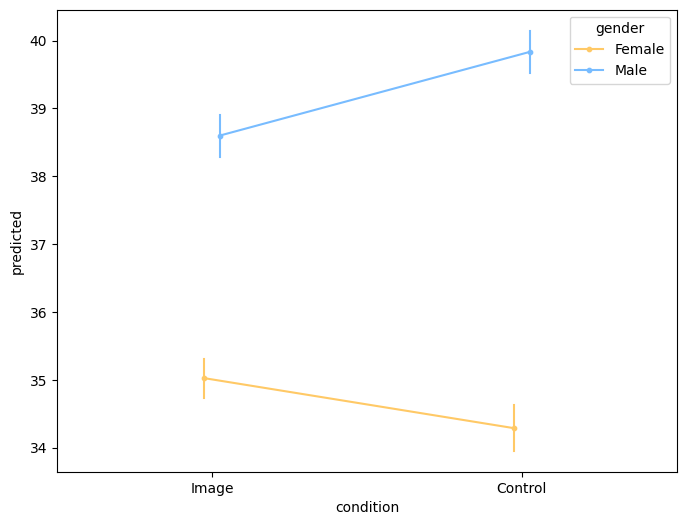

In [372]:
plt.figure(figsize=(8, 6))

sns.pointplot(
    data=treatment_control, 
    x='condition', 
    y='predicted', 
    hue='gender',
    order=['Image', 'Control'],
    palette={'Female': '#FFC966', 'Male': '#78BCFF'},
    markers=['o', 'o'],
    dodge=True,
    errorbar='ci',
    capsize=0,
    linestyles=['-', '-'],
    linewidth=1.5,
    markersize=3
)

plt.ylabel('predicted')
plt.xlabel('condition')
plt.grid(axis='y', alpha=0)
plt.savefig("outputs/grouped_plot.svg", format="svg")
plt.show()

* And the Residuals / Condition plot.

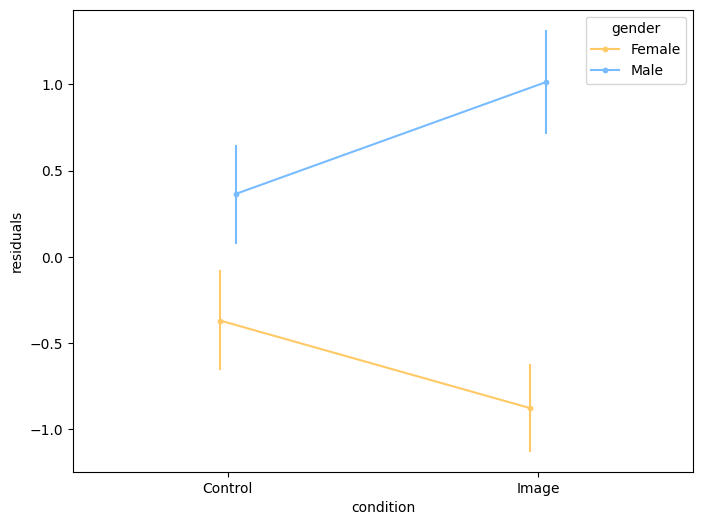

In [373]:
plt.figure(figsize=(8, 6))

sns.pointplot(
    data=treatment_control, 
    x='condition', 
    y='residuals', 
    hue='gender',
    order=['Control', 'Image'],
    palette={'Female': '#FFC966', 'Male': '#78BCFF'},
    markers=['o', 'o'],
    dodge=True,
    errorbar='ci',
    capsize=0,
    linestyles=['-', '-'],
    linewidth=1.5,
    markersize=3
)

plt.ylabel('residuals')
plt.xlabel('condition')
plt.grid(axis='y', alpha=0)
plt.savefig("outputs/grouped_plot_residuals.svg", format="svg")
plt.show()

* Let's explain the results now.

* For the first plot: **Predicted Age**
* The lines for both male and female are nearly horizontal between the Control and Image conditions.
* This is expected. We generated these predictions using a model based only on subject and category.
* Since, a subject's identity does not change whether they are in the control or treatment group, the model predicts roughly the same baseline age for them in both conditions.
* The vertical distance between the lines shows that, in this dataset, men have a significantly higher baseline age (almost 40) compared to women (maximum 35).

* For the second plot: **Residuals**
* This plot visualizes the distortion caused by the filter by showing the residuals
* The residuals is the actual age minus predicted age.
* The important thing here is how the two lines move in opposite directions, creating a widening gap.

* The female line slopes downwards from Control to Image.
* This means that when the Image filter is applied, women are perceived as younger than their predicted baseline identity.
* The residuals drop further into the negative, confirming the strong youthification effect on women.

* The male line trends upwards.
* This indicates that relative to their baseline identity, men in the Image condition are not being youthified in the same way as women.
* The remain above the zero line, meaning they are perceived closer and slightly older than their baseline expectation compared to the control group.

* This scissors effect: the gap between the male and female getting wider in the Image condition, is the visual proof of the amplification.
* On the left, in the control condition, the gender gap in residuals is smaller.
* On the right, in the Image condition, the gap expands significantly.
* Just as we said in our regression above, the filter does not affect everyone equally.
* It disproportionately suppresses the perceived age of women, amplifying the age gap between the genders.

* **Finally** we will proceed to the two ANOVA models.

* The first model will have `condition * gender` as the independent variables, both with Sum encoding.
* And the `age` as the dependent variable.

* For the *Sum* encoding we will use the C(..., Sum)

In [374]:
anova_condition_gender_model = smf.ols(
    formula="age ~ C(condition, Sum) * C(gender, Sum)",
    data=treatment_control
).fit()

* We will generate the ANOVA table.

In [375]:
anova_condition_gender_table = sm.stats.anova_lm(anova_condition_gender_model, typ=2)
anova_condition_gender_table

,sum_sq,df,F,PR(>F)
"C(condition, Sum)",57.586138,1.0,0.607880,4.356088e-01
"C(gender, Sum)",71856.913990,1.0,758.522619,5.017108e-160
"C(condition, Sum):C(gender, Sum)",347.367889,1.0,3.666820,5.553946e-02
Residual,806175.481608,8510.0,NaN,NaN


* The second model will have the `condition * gender` as the independent variables with sum encoding, as well as the `category` and `subj`.
* And the `age` as the dependent variable.

In [376]:
anova_complex_model = smf.ols(
    formula="age ~ C(condition, Sum) * C(gender, Sum) + category + subj",
    data=treatment_control
).fit()

* Generate the second ANOVA table

In [ ]:
anova_complex_table = sm.stats.anova_lm(anova_complex_model, typ=2)
anova_complex_table

,sum_sq,df,F,PR(>F)
"C(condition, Sum)",620.352248,1.0,13.649851,2.217273e-04
"C(gender, Sum)",8055.025507,1.0,177.237846,5.166031e-40
category,230669.638586,53.0,95.764404,0.000000e+00
subj,456023.489314,453.0,22.150246,0.000000e+00
"C(condition, Sum):C(gender, Sum)",329.073698,1.0,7.240736,7.141576e-03
Residual,363807.622227,8005.0,NaN,NaN


: 

* **First Table: Basic ANOVA**
* The first model reveals:
    * Strong main effect of gender: The gender of the uploaded image has a dramatic effect on age estimates, with female images leading to younger estimates than male images.
    * No main effect of condition: On average there is no significant difference between the Image and Control conditions when not accounting for gender.
    * Marginal interaction effect: The interaction between condition and gender is marginally significant, suggesting that the effect of viewing images differs between female and male images.

* **Second Table: Complex ANOVA**
* When we control for occupation category and individual participant differences, the results change substantially:
    * The Condition effect becomes significant: After accounting for category and subject variability, we can now detect a clear effect of the Image vs Control manipulation.
    * Gender effect remains highly significant: The gender bias persists even after controlling for other factors.
    * Strong category effect: Different occupations elicit different age estimates, confirming that some proffesions are associated with older or younger ages.
    * Significant subject effect: There is considerable individual variation in how participant estimate ages.
    * Interaction effect is now clearly significant: The effect of viewing images differs significantly between female and male images.
    

* The second model demonstrates that controlling for occupation type and individual differences reveals effects that were masked by noise in the first model.
* The significant intraction confirms that gender-biased images affect age perception, but this effect operates differently for female vs male images.